<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula%204/MBA_DL_AULA4_05_clip_zero_shot_imagens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 4 | Case 4: classificar imagens sem treinar, com um modelo que lê imagem e texto (CLIP)

**MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio**

**Problema de negócio.** Catalogar fotos: produtos novos no e-commerce, itens de um inventário, imagens de um acervo. As categorias mudam toda semana e quase nunca há fotos rotuladas da categoria nova. Na aula 1, treinar uma CNN do zero com 1.000 fotos deu 60,5%; aproveitar a MobileNetV2 pré-treinada deu 78,5%. Os dois precisaram de fotos rotuladas e de treino.

**A ideia do método.** O CLIP (OpenAI, 2021) tem duas redes: uma lê imagens (um Transformer de visão, ViT: a mesma atenção do notebook 00 aplicada a pedaços da imagem), outra lê texto. As duas foram treinadas juntas em 400 milhões de pares (imagem, legenda) da internet para que **a imagem e a sua legenda fiquem no mesmo lugar** de um espaço de 512 dimensões. Resultado: para classificar, escrevemos os nomes das categorias em texto, transformamos em vetores e vemos de qual a imagem está mais perto. É zero-shot em visão: o "prompt" são os rótulos.

**O que vamos medir.** Acurácia zero-shot nas mesmas 2.000 fotos de teste da aula 1; o efeito da língua dos rótulos; poucas fotos rotuladas (10 por classe) sobre os vetores do CLIP; e trocar as categorias sem treinar nada.

**Roteiro (20 min).** 0. Preparar e carregar as fotos → 1. O CLIP e as duas torres → 2. Fotos em vetores → 3. Rótulos em vetores e zero-shot → 4. A língua do pré-treino → 5. Poucas fotos rotuladas → 6. Trocar as categorias → 7. Guardar.

## 0. Preparar e carregar as fotos

O mesmo `cifar10_amostra_1.zip` da aula 1: pasta `train/` (10.000 fotos), pasta `test/` (2.000 fotos) e `rotulos.csv` com o arquivo, a classe (0 a 9) e o nome. Fotos de 32 × 32 pixels, 10 classes: avião, carro, pássaro, gato, cervo, cachorro, sapo, cavalo, navio, caminhão.

In [1]:
%pip install -q "transformers>=4.56" accelerate

import os                                  # arquivos e pastas
import time                                # cronometrar
import zipfile                             # abrir o zip
import numpy as np                         # vetores
import pandas as pd                        # tabela de rótulos
import matplotlib.pyplot as plt            # mostrar fotos e gráficos
from PIL import Image                      # abrir imagens
import torch
from transformers import CLIPModel, CLIPProcessor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(0)

# achar o zip (pasta atual ou data/); se não achar, pedir upload (Colab)
caminho = None
for c in ["cifar10_amostra_1.zip", "../data/cifar10_amostra_1.zip", "data/cifar10_amostra_1.zip"]:
    if os.path.exists(c):
        caminho = c
if caminho is None:
    from google.colab import files
    print("Envie o arquivo cifar10_amostra_1.zip:")
    caminho = list(files.upload())[0]

zipfile.ZipFile(caminho).extractall("fotos")                 # descompacta em fotos/train, fotos/test, fotos/rotulos.csv
rotulos = pd.read_csv("fotos/rotulos.csv")
treino = rotulos[rotulos["arquivo"].str.startswith("train/")].reset_index(drop=True)
teste = rotulos[rotulos["arquivo"].str.startswith("test/")].reset_index(drop=True)
NOMES_PT = ["avião", "carro", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]   # classe 0 a 9
print("treino", len(treino), "| teste", len(teste))
teste.head(3)

Envie o arquivo cifar10_amostra_1.zip:


Saving cifar10_amostra.zip to cifar10_amostra (1).zip
treino 10000 | teste 2000


,arquivo,classe,nome_classe
0,test/imagem_000.png,8,navio
1,test/imagem_001.png,1,carro
2,test/imagem_002.png,5,cachorro


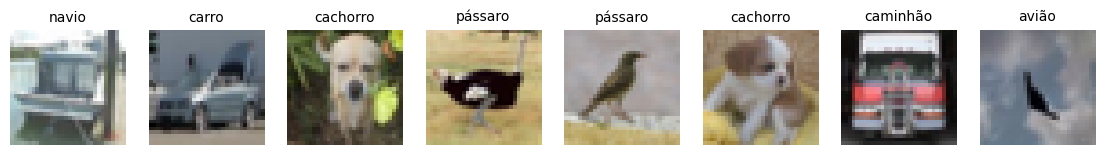

In [2]:
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, (arquivo, classe) in zip(axes, teste[["arquivo", "classe"]].values[:8]):
    ax.imshow(Image.open("fotos/" + arquivo))
    ax.set_title(NOMES_PT[classe], fontsize=10)
    ax.axis("off")
plt.show()

## 1. O CLIP e as duas torres

`openai/clip-vit-base-patch32`: a torre de imagem é um ViT (a imagem é cortada em quadrados de 32 pixels, cada quadrado vira um "token", e um Transformer olha para todos); a torre de texto é um Transformer de texto. Cada torre termina numa **projeção** para o mesmo espaço de 512 números. 151 milhões de parâmetros no total.

O `CLIPProcessor` faz o pré-processamento dos dois lados: redimensiona a imagem para 224 × 224 e normaliza os pixels; tokeniza o texto.

In [3]:
NOME = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(NOME)
proc = CLIPProcessor.from_pretrained(NOME)
clip.eval()

n_img = sum(p.numel() for p in clip.vision_model.parameters())
n_txt = sum(p.numel() for p in clip.text_model.parameters())
print(f"Torre de imagem: {n_img / 1e6:.0f} M parâmetros | torre de texto: {n_txt / 1e6:.0f} M | espaço comum: {clip.config.projection_dim} dimensões")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Torre de imagem: 87 M parâmetros | torre de texto: 63 M | espaço comum: 512 dimensões


## 2. Fotos em vetores

Cada foto passa pela torre de imagem e pela projeção; sai um vetor de 512 números, que normalizamos (comprimento 1) para a similaridade ser o produto escalar, como no RAG. Fazemos isso **uma vez** para as 2.000 fotos de teste e guardamos: todas as seções seguintes reutilizam a matriz. Em CPU leva cerca de 1 a 2 minutos; em GPU, segundos.

In [4]:
def vetores_imagem(arquivos, lote=50):
    saida = []
    with torch.no_grad():
        for i in range(0, len(arquivos), lote):
            imagens = [Image.open("fotos/" + a).convert("RGB") for a in arquivos[i:i + lote]]   # abre o lote
            pixels = proc(images=imagens, return_tensors="pt")["pixel_values"]                   # redimensiona e normaliza
            h = clip.vision_model(pixel_values=pixels).pooler_output                             # a torre de imagem: 768 números
            v = clip.visual_projection(h)                                                        # projeção para o espaço comum: 512
            saida.append(v / v.norm(dim=1, keepdim=True))                                        # comprimento 1
    return torch.cat(saida).numpy()

t0 = time.time()
I_teste = vetores_imagem(list(teste["arquivo"]))
print("Matriz das fotos de teste:", I_teste.shape, f"| {time.time() - t0:.0f} s")

Matriz das fotos de teste: (2000, 512) | 282 s


## 3. Rótulos em vetores, e a classificação sem treino

Agora o lado do texto. Cada categoria vira uma frase ("a photo of a cat."), a frase passa pela torre de texto e pela projeção, sai um vetor de 512 números no **mesmo espaço** das fotos. Classificar = para cada foto, achar o rótulo com maior similaridade. Nenhum peso treinado, nenhuma foto rotulada usada.

O molde "a photo of a {}." em vez da palavra solta é o "prompt engineering" do CLIP: o modelo viu legendas, não palavras isoladas.

In [5]:
def vetores_texto(frases):
    with torch.no_grad():
        entrada = proc(text=frases, return_tensors="pt", padding=True)       # tokeniza
        h = clip.text_model(**entrada).pooler_output                           # a torre de texto
        v = clip.text_projection(h)                                            # projeção para o espaço comum: 512
        return (v / v.norm(dim=1, keepdim=True)).numpy()

NOMES_EN = ["airplane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
T_en = vetores_texto([f"a photo of a {n}." for n in NOMES_EN])
print("Matriz dos rótulos:", T_en.shape)

similaridade = I_teste @ T_en.T                                  # 2000 fotos x 10 rótulos
palpite = similaridade.argmax(axis=1)                            # o rótulo mais parecido com cada foto
acc_zero_en = (palpite == teste["classe"].values).mean()
print(f"Zero-shot, rótulos em inglês: acurácia {acc_zero_en:.1%} nas {len(teste)} fotos de teste (sem nenhum treino)")
print("Aula 1, mesmas fotos: CNN do zero com 1.000 fotos 60,5% | MobileNetV2 congelada 77,0% | MobileNetV2 ajustada 78,5%")

Matriz dos rótulos: (10, 512)
Zero-shot, rótulos em inglês: acurácia 87.9% nas 2000 fotos de teste (sem nenhum treino)
Aula 1, mesmas fotos: CNN do zero com 1.000 fotos 60,5% | MobileNetV2 congelada 77,0% | MobileNetV2 ajustada 78,5%


⏱ **Checkpoint 1:** qual foi a acurácia zero-shot? Compare com os 78,5% da aula 1, que precisaram de 1.000 fotos rotuladas e 5 épocas de treino.

### Por classe e matriz de confusão

Onde o CLIP erra? Nas fotos de 32 pixels esticadas para 224, as classes parecidas (gato e cachorro, carro e caminhão) se confundem. Veja também o par cervo e cavalo.

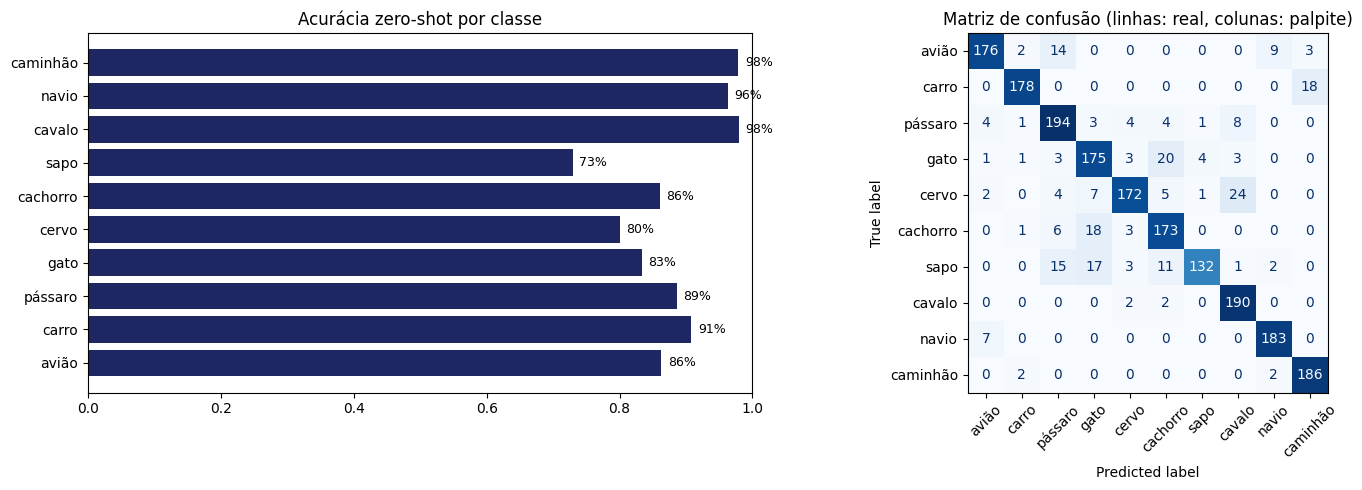

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

por_classe = [(palpite[teste["classe"] == c] == c).mean() for c in range(10)]
axes[0].barh(NOMES_PT, por_classe, color="#1E2761")
axes[0].set_xlim(0, 1)
axes[0].set_title("Acurácia zero-shot por classe")
for i, v in enumerate(por_classe):
    axes[0].text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)

ConfusionMatrixDisplay(confusion_matrix(teste["classe"], palpite), display_labels=NOMES_PT).plot(ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=45)
axes[1].set_title("Matriz de confusão (linhas: real, colunas: palpite)")
plt.tight_layout()
plt.show()

## 4. A língua do pré-treino

O CLIP foi treinado com legendas em inglês. Troque os rótulos para português e meça de novo. Nada mais muda. O resultado mostra o que "pré-treinado" significa: o modelo sabe o que viu, na língua em que viu. Para rótulos em português com qualidade há versões multilíngues do CLIP; o código é o mesmo.

In [7]:
T_pt = vetores_texto([f"uma foto de um {n}." for n in NOMES_PT])
palpite_pt = (I_teste @ T_pt.T).argmax(axis=1)
acc_zero_pt = (palpite_pt == teste["classe"].values).mean()
print(f"Zero-shot, rótulos em português: {acc_zero_pt:.1%} | em inglês: {acc_zero_en:.1%}")

# e sem o molde "a photo of a ...": só a palavra
T_palavra = vetores_texto(NOMES_EN)
acc_palavra = ((I_teste @ T_palavra.T).argmax(axis=1) == teste["classe"].values).mean()
print(f"Zero-shot, só a palavra em inglês (sem o molde): {acc_palavra:.1%}")

Zero-shot, rótulos em português: 61.7% | em inglês: 87.9%
Zero-shot, só a palavra em inglês (sem o molde): 86.2%


## 5. Poucas fotos rotuladas: 10 por classe sobre os vetores do CLIP

Mesma receita do BERT congelado do notebook 00 e da MobileNet congelada da aula 1: os vetores do CLIP viram as entradas de uma regressão logística. Com **10 fotos por classe** (100 no total) e depois com 100 por classe (1.000, como a aula 1). Isso é o que se faz quando os rótulos do negócio não são "gato" e "cachorro", mas "peça conforme" e "peça com rebarba": o texto não descreve, mas 10 exemplos descrevem.

In [8]:
resultados = {}
for por_classe in [10, 100]:
    amostra = treino.groupby("classe").sample(por_classe, random_state=0)       # N fotos de cada classe
    t0 = time.time()
    I_amostra = vetores_imagem(list(amostra["arquivo"]))
    clf = LogisticRegression(max_iter=2000).fit(I_amostra, amostra["classe"])  # treina só a regressão (5.130 pesos)
    acc = (clf.predict(I_teste) == teste["classe"].values).mean()
    resultados[por_classe] = acc
    print(f"{por_classe:3d} fotos por classe ({len(amostra):4d} no total): acurácia {acc:.1%} | {time.time() - t0:.0f} s")
print("\nAula 1, MobileNetV2 congelada + regressão logística: na casa de 70% com 10 por classe | 77,0% com 100 por classe (com camada densa)")

 10 fotos por classe ( 100 no total): acurácia 87.0% | 11 s
100 fotos por classe (1000 no total): acurácia 91.6% | 110 s

Aula 1, MobileNetV2 congelada + regressão logística: na casa de 70% com 10 por classe | 77,0% com 100 por classe (com camada densa)


### A comparação da aula 1 até aqui

Todas as linhas foram medidas nas mesmas 2.000 fotos de teste.

In [9]:
comp = pd.DataFrame([
    ["CNN do zero (aula 1)",                       "1.000 fotos rotuladas, 5 épocas", "60,5%"],
    ["MobileNetV2 congelada + camada nova (aula 1)", "1.000 fotos rotuladas, 5 épocas", "77,0%"],
    ["MobileNetV2 ajustada (aula 1)",              "1.000 fotos rotuladas, 5 épocas", "78,5%"],
    ["CLIP zero-shot, rótulos em inglês",          "0 fotos rotuladas",               f"{acc_zero_en:.1%}".replace(".", ",")],
    ["CLIP zero-shot, rótulos em português",       "0 fotos rotuladas",               f"{acc_zero_pt:.1%}".replace(".", ",")],
    ["CLIP congelado + regressão logística",       "100 fotos rotuladas (10 por classe)", f"{resultados[10]:.1%}".replace(".", ",")],
    ["CLIP congelado + regressão logística",       "1.000 fotos rotuladas (100 por classe)", f"{resultados[100]:.1%}".replace(".", ",")],
], columns=["abordagem", "dados e treino", "acurácia (2.000 fotos de teste)"])
comp

,abordagem,dados e treino,acurácia (2.000 fotos de teste)
0,CNN do zero (aula 1),"1.000 fotos rotuladas, 5 épocas","60,5%"
1,MobileNetV2 congelada + camada nova (aula 1),"1.000 fotos rotuladas, 5 épocas","77,0%"
2,MobileNetV2 ajustada (aula 1),"1.000 fotos rotuladas, 5 épocas","78,5%"
3,"CLIP zero-shot, rótulos em inglês",0 fotos rotuladas,"87,9%"
4,"CLIP zero-shot, rótulos em português",0 fotos rotuladas,"61,7%"
5,CLIP congelado + regressão logística,100 fotos rotuladas (10 por classe),"87,0%"
6,CLIP congelado + regressão logística,1.000 fotos rotuladas (100 por classe),"91,6%"


**Leitura de negócio.** O degrau mais caro já foi pago por quem treinou o CLIP em 400 milhões de pares. O que sobra para a empresa é barato: escrever rótulos (zero fotos), ou juntar 10 exemplos por categoria. A CNN treinada do zero na aula 1 só faz sentido quando o domínio é tão específico que nenhum pré-treino o cobre (imagens médicas raras, sinais de sensor); e mesmo aí o primeiro teste é um modelo pré-treinado.

## 6. Trocar as categorias sem treinar nada

O que uma CNN treinada não faz: mudar de pergunta. Aqui, as mesmas fotos, outra pergunta: "é um animal ou um veículo?". Escrevemos dois rótulos novos e medimos. Nenhuma linha de treino. Em seguida, uma pergunta que a CIFAR nunca rotulou: "está em terra, no ar ou na água?".

Animal ou veículo, zero-shot: 92.3%


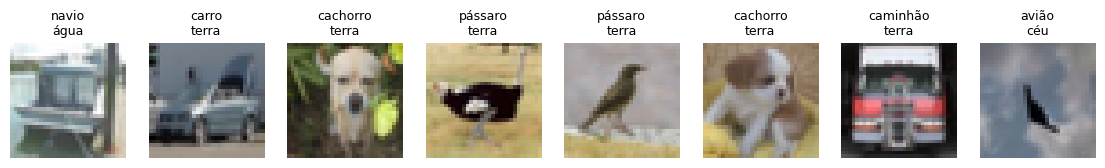

In [10]:
# as 10 classes agrupadas: 0 avião, 1 carro, 8 navio, 9 caminhão = veículo; o resto = animal
e_animal = teste["classe"].isin([2, 3, 4, 5, 6, 7]).values.astype(int)        # 1 = animal, 0 = veículo

T_grupo = vetores_texto(["a photo of a vehicle.", "a photo of an animal."])    # índice 0 = veículo, 1 = animal
palpite_grupo = (I_teste @ T_grupo.T).argmax(axis=1)
print(f"Animal ou veículo, zero-shot: {(palpite_grupo == e_animal).mean():.1%}")

# uma pergunta sem gabarito: mostramos a resposta para algumas fotos
T_meio = vetores_texto(["a photo of something on land.", "a photo of something in the sky.", "a photo of something in the water."])
meios = ["terra", "céu", "água"]
palpite_meio = (I_teste @ T_meio.T).argmax(axis=1)

fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, k in zip(axes, range(8)):
    ax.imshow(Image.open("fotos/" + teste["arquivo"][k]))
    ax.set_title(f"{NOMES_PT[teste['classe'][k]]}\n{meios[palpite_meio[k]]}", fontsize=9)
    ax.axis("off")
plt.show()

### Sua foto, seus rótulos (opcional)

Suba uma foto qualquer e escreva os rótulos que quiser (em inglês, por causa do pré-treino). O modelo responde a probabilidade de cada um. É o mesmo mecanismo de todo o notebook.

In [11]:
try:
    from google.colab import files
    print("Envie uma foto (jpg ou png):")
    enviado = list(files.upload())[0]
    MEUS_ROTULOS = ["a photo of a person", "a photo of a building", "a photo of food", "a photo of a landscape", "a photo of a document"]
    with torch.no_grad():
        pixels = proc(images=[Image.open(enviado).convert("RGB")], return_tensors="pt")["pixel_values"]
        v = clip.visual_projection(clip.vision_model(pixel_values=pixels).pooler_output)
        v = (v / v.norm(dim=1, keepdim=True)).numpy()
    sims = (v @ vetores_texto(MEUS_ROTULOS).T)[0]
    prob = np.exp(sims * 100) / np.exp(sims * 100).sum()         # softmax com a escala do CLIP (100)
    for r, p in sorted(zip(MEUS_ROTULOS, prob), key=lambda x: -x[1]):
        print(f"{p:5.0%} | {r}")
except Exception as e:
    print("Pulei (fora do Colab ou sem upload):", type(e).__name__)

Envie uma foto (jpg ou png):


Saving images (9).jpg to images (9).jpg
  29% | a photo of a document
  27% | a photo of a building
  22% | a photo of a person
  13% | a photo of food
   9% | a photo of a landscape


## 7. Guardar o resultado

In [12]:
import json
resultado = {"modelo": NOME, "n_teste": int(len(teste)),
             "acc_zero_shot_en": round(float(acc_zero_en), 4), "acc_zero_shot_pt": round(float(acc_zero_pt), 4),
             "acc_zero_shot_palavra": round(float(acc_palavra), 4),
             "acc_10_por_classe": round(float(resultados[10]), 4), "acc_100_por_classe": round(float(resultados[100]), 4)}
json.dump(resultado, open("resultado_case4_clip.json", "w"), indent=2)
np.save("vetores_clip_teste.npy", I_teste)
print(resultado)

{'modelo': 'openai/clip-vit-base-patch32', 'n_teste': 2000, 'acc_zero_shot_en': 0.8795, 'acc_zero_shot_pt': 0.6165, 'acc_zero_shot_palavra': 0.862, 'acc_10_por_classe': 0.8695, 'acc_100_por_classe': 0.916}


## Para discutir

1. Que fotos a sua empresa tem que ninguém classifica porque "não dá tempo"? Os rótulos cabem numa frase em inglês?
2. O CLIP caiu de 88% para 62% ao trocar a língua dos rótulos. Que outras "línguas" (jargão, fotos de câmera industrial, raio-X) podem estar fora do pré-treino do seu problema?
3. Zero fotos rotuladas deram mais do que 1.000 fotos e 5 épocas de treino na aula 1. O que isso muda na forma de começar um projeto de visão?

**Encerramento da disciplina:** o fio das quatro aulas e a pergunta de decisão: prompt, RAG, fine-tuning ou treinar do zero?